# Person 2 — SIRTA source, EDA and reproducible cleaning
Source: [Serious Injury Response, Tracking & Analysis Program (xeqp-qz8h)](https://data.cityofnewyork.us/d/xeqp-qz8h), NYC DOT. This covers crashes analyzed and reported through SIRTA, rather than every NYC road collision.

This notebook was added during the 2026-11-07 audit. The original transportation cleaning notebook was absent from the repository history. The method below was recovered by comparing the archived official source with every field of the supplied cleaned CSV; it reproduces that snapshot exactly. It documents a verifiable pipeline, but does not establish who originally performed these steps. Run offline from the repository root. Source files, retrieval date, URLs and hashes are in `data/raw/manifest.json`.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, str(Path("scripts").resolve()))
from cleaning import clean_transport

df_transport_raw = pd.read_csv("data/raw/df_transport_raw.csv", low_memory=False)
print("Raw shape:", df_transport_raw.shape)
display(df_transport_raw.head())
df_transport_raw.info()
display(df_transport_raw.describe(include="all").T)


Raw shape: (13754, 23)


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,...,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,4492364.0,2022-01-01T00:00:00.000,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,2022-01-01T00:00:00.000,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,2022-01-01T00:00:00.000,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223.0,2022-01-01T00:00:00.000,10:42,43.0,Bronx,0.0,1.0,0.0,40.823673,-73.87233,...,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418.0,2022-01-01T00:00:00.000,20:55,49.0,Bronx,0.0,1.0,0.0,40.863945,-73.86452,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13754 entries, 0 to 13753
Data columns (total 23 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   open_data_crash_id                      13310 non-null  float64
 1   crash_date                              13310 non-null  object 
 2   crash_time                              13310 non-null  object 
 3   crash_police_precinct                   13310 non-null  float64
 4   crash_borough                           13255 non-null  object 
 5   total_non_severe_injuries               13310 non-null  float64
 6   total_severe_injuries                   13310 non-null  float64
 7   total_fatalities                        13310 non-null  float64
 8   latitude                                10868 non-null  float64
 9   longitude                               10868 non-null  float64
 10  on_street                               10718 non-null  ob

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
open_data_crash_id,13310.0,NaN,NaN,NaN,7271532.868295,11289301.231011,2126022.0,4612503.25,4718837.5,4814222.75,121326075.0
crash_date,13310,1641,2022-05-21T00:00:00.000,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crash_time,13310,1728,00:00,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crash_police_precinct,13310.0,NaN,NaN,NaN,67.837866,34.683947,1.0,42.0,68.0,104.0,123.0
crash_borough,13255,5,Brooklyn,3954,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_non_severe_injuries,13310.0,NaN,NaN,NaN,0.270473,0.836031,0.0,0.0,0.0,0.0,19.0
total_severe_injuries,13310.0,NaN,NaN,NaN,1.011495,0.451514,0.0,1.0,1.0,1.0,7.0
total_fatalities,13310.0,NaN,NaN,NaN,0.082795,0.294304,0.0,0.0,0.0,0.0,5.0
latitude,10868.0,NaN,NaN,NaN,40.730641,0.083378,40.499672,40.667854,40.72671,40.800663,40.912468
longitude,10868.0,NaN,NaN,NaN,-73.921537,0.081929,-74.24857,-73.96879,-73.923693,-73.874742,-73.7006


## Missing values, duplicates and geographic selection
Blank ZIP codes cannot be assigned to `zip_code + year` without independent geography. The recovered recipe removes exact duplicate rows, then excludes rows with missing `zipcode` from the cleaned ZIP-level table. Missing coordinates and optional descriptive fields are retained; they do not imply a zero injury count. Repeated IDs after selection trigger an error rather than an arbitrary choice.

The raw source starts in January 2022. The retained, ZIP-known subset starts in October 2022 because earlier records have missing ZIPs. Therefore the cleaned date range does **not** establish when SIRTA began. Even 2023–2025 span complete calendar years but omit crashes with unknown ZIPs; they are not complete citywide collision totals.


In [2]:
missing = df_transport_raw.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({"missing_count": missing, "missing_percent": missing / len(df_transport_raw) * 100}))
print("Exact duplicate rows:", int(df_transport_raw.duplicated().sum()))
print("Missing IDs:", int(df_transport_raw.open_data_crash_id.isna().sum()))
print("Missing ZIP rows:", int(df_transport_raw.zipcode.isna().sum()))
dates = pd.to_datetime(df_transport_raw.crash_date, errors="coerce")
coverage = df_transport_raw.assign(source_year=dates.dt.year, zip_known=df_transport_raw.zipcode.notna())
display(coverage.groupby("source_year").agg(raw_rows=("zip_known", "size"),
    zip_known_rows=("zip_known", "sum")))
display(df_transport_raw.crash_borough.value_counts(dropna=False))


,missing_count,missing_percent
highway_reference_marker,12702,92.351316
address,11177,81.263632
bin,10967,79.736804
bbl,10967,79.736804
census_tract_2020_,9886,71.877272
neighborhood_tabulation_area_nta_2020_,9886,71.877272
council_district,9883,71.855460
community_board,9883,71.855460
zipcode,5682,41.311618
cross_street,5642,41.020794


Exact duplicate rows: 3
Missing IDs: 444
Missing ZIP rows: 5682


,raw_rows,zip_known_rows
source_year,,
2022.0,2879,469
2023.0,3016,2055
2024.0,3116,2180
2025.0,2947,2367
2026.0,1352,1001


crash_borough
Brooklyn         3954
Queens           3282
Manhattan        2733
Bronx            2617
Staten Island     669
NaN               499
Name: count, dtype: int64

## Injury values and outliers
Counts are converted by CSV numeric inference and checked for missing, fractional or negative values in retained records. Large counts are not removed merely for exceeding an IQR fence: a serious crash can injure several people. ZIP `10000` occurs in 44 source rows associated with Central Park/Manhattan. It is preserved as a source code and flagged for geographic validation; no address or ZIP is invented. Those ZIP-years do not match any housing ZIP-year in the saved integration.


,total_non_severe_injuries,total_severe_injuries,total_fatalities
count,13310.000000,13310.000000,13310.000000
mean,0.270473,1.011495,0.082795
std,0.836031,0.451514,0.294304
min,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000
50%,0.000000,1.000000,0.000000
75%,0.000000,1.000000,0.000000
max,19.000000,7.000000,5.000000


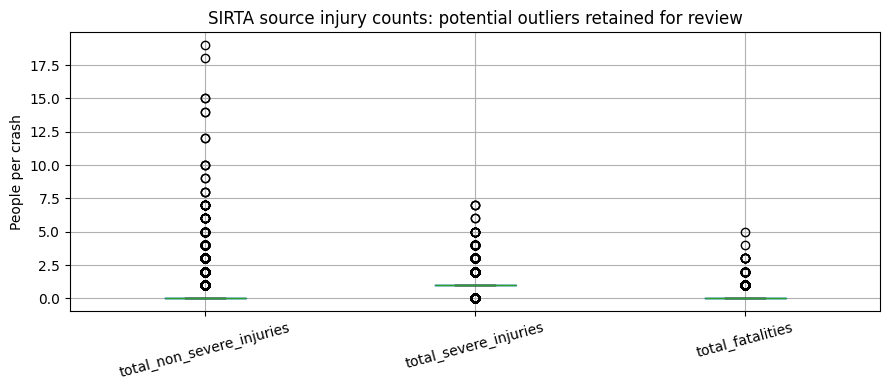

total_non_severe_injuries above IQR fence: 2172
total_severe_injuries above IQR fence: 824
total_fatalities above IQR fence: 1047


In [3]:
counts = ["total_non_severe_injuries", "total_severe_injuries", "total_fatalities"]
display(df_transport_raw[counts].describe())
fig, ax = plt.subplots(figsize=(9, 4))
df_transport_raw[counts].boxplot(ax=ax)
ax.set_title("SIRTA source injury counts: potential outliers retained for review")
ax.set_ylabel("People per crash")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
for column in counts:
    q1, q3 = df_transport_raw[column].quantile([0.25, 0.75])
    print(column, "above IQR fence:", int((df_transport_raw[column] > q3 + 1.5 * (q3-q1)).sum()))


In [4]:
df_transport_clean = clean_transport(df_transport_raw)
for column in counts:
    values = df_transport_clean[column]
    assert values.notna().all() and values.ge(0).all() and values.mod(1).eq(0).all(), column
assert df_transport_clean.zip_code.str.fullmatch(r"\d{5}").all()
assert set(df_transport_clean.borough) == {"Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"}
assert df_transport_clean[["zip_code", "borough", "year"]].notna().all().all()
print("Clean shape:", df_transport_clean.shape)
print("Missing coordinates retained:", int(df_transport_clean.latitude.isna().sum()))
print("Source ZIP10000 retained:", int(df_transport_clean.zip_code.eq("10000").sum()))
display(df_transport_clean.groupby("year").agg(rows=("zip_code", "size"),
    first_crash=("crash_date", "min"), last_crash=("crash_date", "max")))


Clean shape:

 (8072, 26)
Missing coordinates retained: 1295
Source ZIP10000 retained: 44


,rows,first_crash,last_crash
year,,,
2022,469,2022-10-01,2022-12-31
2023,2055,2023-01-01,2023-12-31
2024,2180,2024-01-01,2024-12-31
2025,2367,2025-01-01,2025-12-30
2026,1001,2026-01-01,2026-06-30


In [5]:
# Exact source-field comparison after equivalent date/ZIP representation.
supplied = pd.read_csv("df_transport_clean.csv", dtype={"zip_code": "string"}, low_memory=False)
supplied["crash_date"] = pd.to_datetime(supplied["crash_date"])
key = "open_data_crash_id"
pd.testing.assert_frame_equal(df_transport_clean.sort_values(key).reset_index(drop=True),
    supplied.sort_values(key).reset_index(drop=True), check_dtype=False)
print("PASS: all supplied transportation fields reproduced from the archived raw source.")
df_transport_clean.to_csv("df_transport_clean.csv", index=False)


PASS: all supplied transportation fields reproduced from the archived raw source.


## Result and limitations
The archived source contains 13,754 rows and 23 columns. Excluding the 5,682 rows with unknown ZIP yields the supplied 8,072 rows and 26 columns, with `zip_code`, `borough` and integer `year`. Exact duplicates are confined to excluded records in this snapshot. All 8,072 retained crash IDs are unique.

No missing injury values are filled with zero; no crash is dropped because coordinates are unavailable. Unknown geographic records are absent from ZIP-level results, which creates selection bias. The source ZIP 10000 needs independent geography validation. Source date coverage and annual ZIP coverage should be reviewed on every refresh. The archived inputs are preserved and downstream aggregates must be rebuilt together if the policy changes.

The two assigned research questions and figures are in `Person2_Research_Questions.ipynb` (RQ3 and RQ4).
